# Stage 0 — Explore CrackSeg9k

Crack segmentation and measurement project. Explanations: see the study guide.

In [1]:
# Cell 1 — Imports and settings
from pathlib import Path
import re
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

DATA_ROOT = Path("/kaggle/input")       # where Kaggle mounts attached datasets
OUT_DIR = Path("/kaggle/working")       # files saved here appear in the notebook's Output tab
SEED = 0
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# Cell 2 — Locate the image and mask folders
wanted = {"Images", "Images-2", "Masks", "Heads"}
folders = {p.name: p for p in DATA_ROOT.rglob("*") if p.is_dir() and p.name in wanted}
split_files = {p.name: p for p in DATA_ROOT.rglob("*.txt") if p.name in {"train.txt", "test.txt"}}

for name, path in sorted(folders.items()):
    print(f"{name:9s} {len(list(path.glob('*.png'))):5d} png  {path}")
print("Split files:", sorted(split_files))

Heads      9159 png  /kaggle/input/datasets/atharv0919/crackseg9k/Final-Dataset-Vol1/Final-Dataset-Vol1/Final_Masks/Heads
Images     5413 png  /kaggle/input/datasets/atharv0919/crackseg9k/Final-Dataset-Vol1/Final-Dataset-Vol1/Images
Images-2   3746 png  /kaggle/input/datasets/atharv0919/crackseg9k/Final-Dataset-Vol2/Final-Dataset-Vol2/Images-2
Masks      9159 png  /kaggle/input/datasets/atharv0919/crackseg9k/Final-Dataset-Vol1/Final-Dataset-Vol1/Final_Masks/Masks
Split files: ['test.txt', 'train.txt']


In [3]:
# Cell 3 — Build an index: one row per image
SOURCE_RULES = [  # file-name prefix -> source dataset
    ("CRACK500", "CRACK500"), ("Rissbilder", "Rissbilder"), ("noncrack", "Noncrack"),
    ("DeepCrack", "DeepCrack"), ("Volker", "Volker"), ("GAPS384", "GAPS384"),
    ("cracktree200", "CrackTree200"), ("CFD", "CFD"), ("Ceramic", "Ceramic"),
]

def source_of(name):
    for prefix, source in SOURCE_RULES:
        if name.startswith(prefix):
            return source
    return "Misc"  # a_*, b_*, c_*, d_*, h_* files

def parent_of(name, source):
    """ID of the original photo a crop was cut from (crops of one photo must stay in one split)."""
    stem = name.rsplit(".", 1)[0]
    parts = stem.split("_")
    if source in ("CRACK500", "GAPS384"):
        return "_".join(parts[1:3])            # CRACK500_20160306_104456_641_1081 -> 20160306_104456
    if source == "Rissbilder":
        return parts[3]                        # Rissbilder_for_Florian_9S6A2889_... -> 9S6A2889
    if source == "Volker":
        return parts[1]                        # Volker_DSC01670_... -> DSC01670
    if source == "Noncrack":
        return "_".join(parts[:5])             # ..._concrete_wall_6_3 -> ..._concrete_wall_6
    if source == "DeepCrack":
        return stem.split("_", 1)[1].split("-")[0]   # DeepCrack_IMG27-1 -> IMG27
    if source == "Misc":
        return "_".join(parts[:2])             # a_130_7 -> a_130
    return stem                                # CFD, CrackTree200, Ceramic: one image per photo

rows = []
for folder in ("Images", "Images-2"):
    for img_path in sorted(folders[folder].glob("*.png")):
        name = img_path.name
        source = source_of(name)
        rows.append({
            "name": name,
            "source": source,
            "parent": f"{source}/{parent_of(name, source)}",
            "image": str(img_path),
            "mask": str(folders["Masks"] / name),
            "head": str(folders["Heads"] / name),
        })
df = pd.DataFrame(rows)
df["mask_exists"] = df["mask"].map(lambda p: Path(p).exists())
print(f"{len(df)} images, {df['mask_exists'].sum()} with a matching mask")
df.head()

9159 images, 9159 with a matching mask


,name,source,parent,image,mask,head,mask_exists
0,DeepCrack_11111.png,DeepCrack,DeepCrack/11111,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,True
1,DeepCrack_11112.png,DeepCrack,DeepCrack/11112,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,True
2,DeepCrack_11115.png,DeepCrack,DeepCrack/11115,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,True
3,DeepCrack_11116-1.png,DeepCrack,DeepCrack/11116,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,True
4,DeepCrack_11116-4.png,DeepCrack,DeepCrack/11116,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,/kaggle/input/datasets/atharv0919/crackseg9k/F...,True


              images  photos  crops_per_photo
source                                       
CRACK500        3126     442              7.1
Rissbilder      2736     180             15.2
Noncrack        1411     104             13.6
DeepCrack        443     143              3.1
Volker           427      58              7.4
GAPS384          383     239              1.6
Misc             240      76              3.2
CrackTree200     175     175              1.0
CFD              118     118              1.0
Ceramic          100     100              1.0


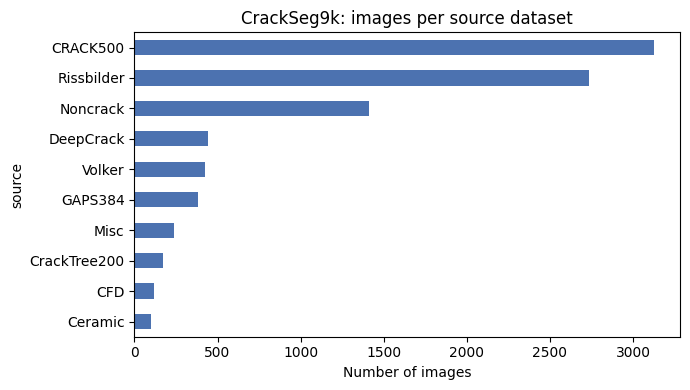

In [4]:
# Cell 4 — Images and original photos per source
summary = (df.groupby("source")
             .agg(images=("name", "size"), photos=("parent", "nunique"))
             .sort_values("images", ascending=False))
summary["crops_per_photo"] = (summary["images"] / summary["photos"]).round(1)
print(summary)

ax = summary["images"].plot.barh(figsize=(7, 4), color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("Number of images")
ax.set_title("CrackSeg9k: images per source dataset")
plt.tight_layout()
plt.show()

In [5]:
# Cell 5 — Image sizes and colour modes
def header_info(path):
    with Image.open(path) as im:   # opening reads only the file header, so this is fast
        return im.size, im.mode

info = [header_info(p) for p in tqdm(df["image"], desc="image headers")]
df["width"] = [s[0] for s, _ in info]
df["height"] = [s[1] for s, _ in info]
df["img_mode"] = [m for _, m in info]

print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print(df["img_mode"].value_counts())

image headers:   0%|          | 0/9159 [00:00<?, ?it/s]

width  height
400    400       9159
dtype: int64
img_mode
RGB    9159
Name: count, dtype: int64


In [6]:
# Cell 6 — What values do the masks contain?
sample = df.sample(min(200, len(df)), random_state=SEED)
values, modes = set(), set()
for p in sample["mask"]:
    with Image.open(p) as im:
        modes.add(im.mode)
        values.update(np.unique(np.array(im.convert("L"))).tolist())
print("Mask modes:", modes)
print("Distinct grey values in 200 masks:", len(values), sorted(values)[:10], "...", sorted(values)[-5:])

Mask modes: {'L'}
Distinct grey values in 200 masks: 256 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] ... [251, 252, 253, 254, 255]


masks:   0%|          | 0/9159 [00:00<?, ?it/s]

              mean_crack_pct  empty_masks_pct
source                                       
Noncrack                0.02            70.16
CrackTree200            0.26             0.00
GAPS384                 1.14             0.00
Rissbilder              1.60             0.58
CFD                     1.61             0.00
Ceramic                 2.06             0.00
Volker                  3.18             0.23
DeepCrack               3.51             0.00
Misc                    4.20             0.00
CRACK500                5.97             0.00

Overall: 3.04% of pixels are crack


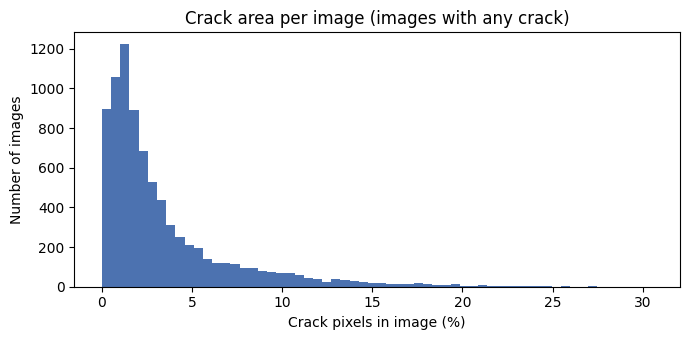

In [7]:
# Cell 7 — How much of each image is crack? (class imbalance)
def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)   # works for 0/255 and 0/1 masks

df["crack_frac"] = [load_mask(p).mean() for p in tqdm(df["mask"], desc="masks")]

per_source = df.groupby("source")["crack_frac"].agg(
    mean_crack_pct=lambda x: 100 * x.mean(),
    empty_masks_pct=lambda x: 100 * (x == 0).mean(),
).round(2).sort_values("mean_crack_pct")
print(per_source)
print(f"\nOverall: {100 * df['crack_frac'].mean():.2f}% of pixels are crack")

plt.figure(figsize=(7, 3.5))
plt.hist(100 * df.loc[df["crack_frac"] > 0, "crack_frac"], bins=60, color="#4C72B0")
plt.xlabel("Crack pixels in image (%)")
plt.ylabel("Number of images")
plt.title("Crack area per image (images with any crack)")
plt.tight_layout()
plt.show()

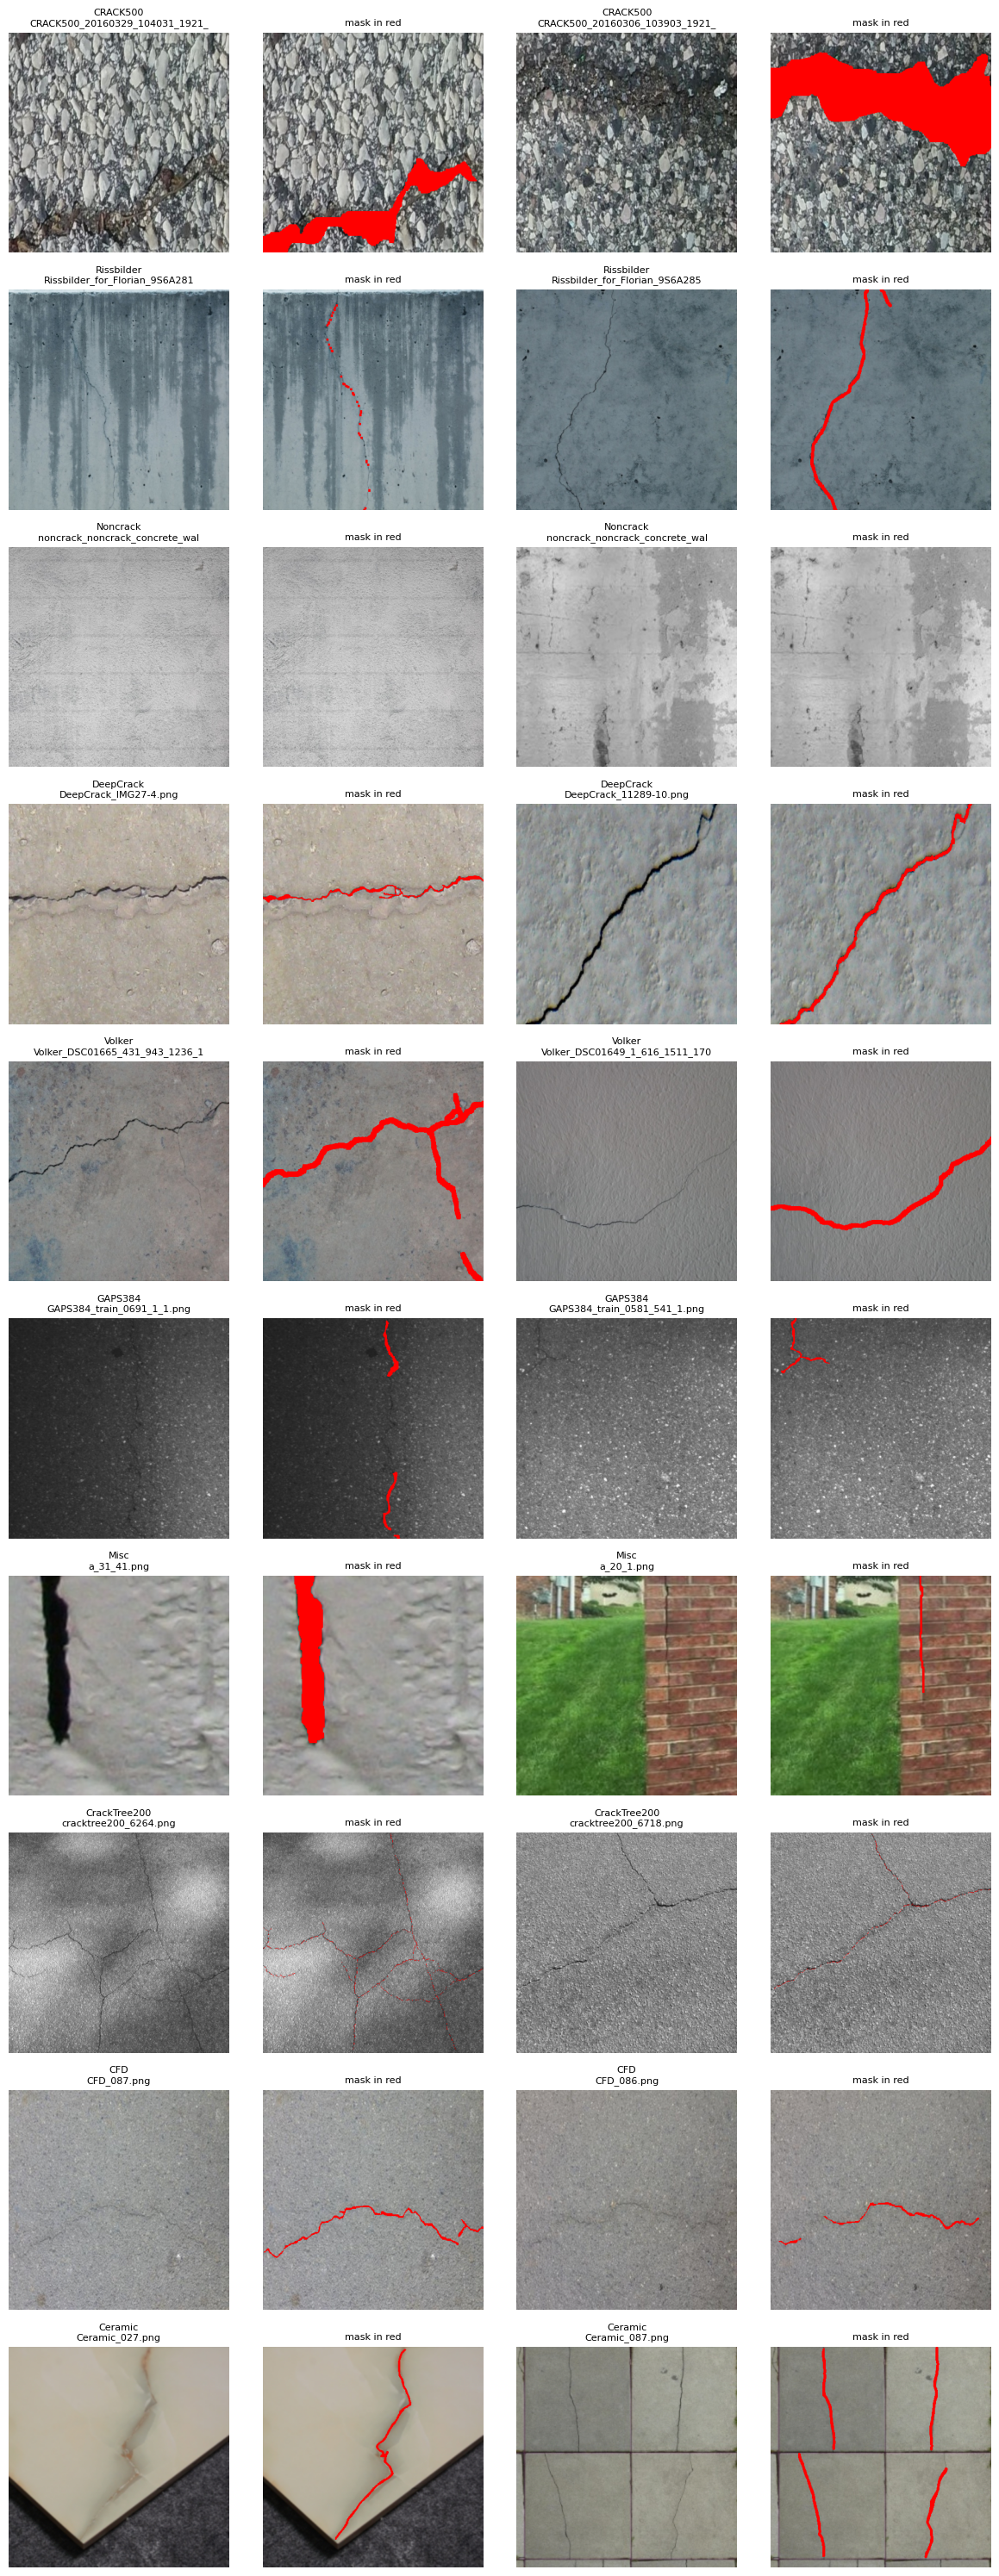

In [8]:
# Cell 8 — Look at examples from every source
def overlay(img, mask, color=(255, 0, 0)):
    out = np.array(img.convert("RGB")).copy()
    out[mask] = color
    return out

sources = summary.index.tolist()
fig, axes = plt.subplots(len(sources), 4, figsize=(12, 3 * len(sources)))
for r, source in enumerate(sources):
    picks = df[df["source"] == source].sample(2, random_state=SEED)
    for k, (_, row) in enumerate(picks.iterrows()):
        img = Image.open(row["image"])
        axes[r, 2 * k].imshow(img)
        axes[r, 2 * k].set_title(f"{source}\n{row['name'][:30]}", fontsize=8)
        axes[r, 2 * k + 1].imshow(overlay(img, load_mask(row["mask"])))
        axes[r, 2 * k + 1].set_title("mask in red", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

head_size
480x480    200
Name: count, dtype: int64
       head_values  head_pct  mask_pct  iou_with_mask
count      200.000   200.000   200.000        200.000
mean       105.900     0.636     2.455          0.088
std         25.765     0.495     2.704          0.107
min         42.000     0.031     0.000          0.000
25%         87.750     0.253     0.571          0.000
50%        109.000     0.509     1.526          0.039
75%        124.000     0.892     3.385          0.158
max        164.000     2.876    13.268          0.469


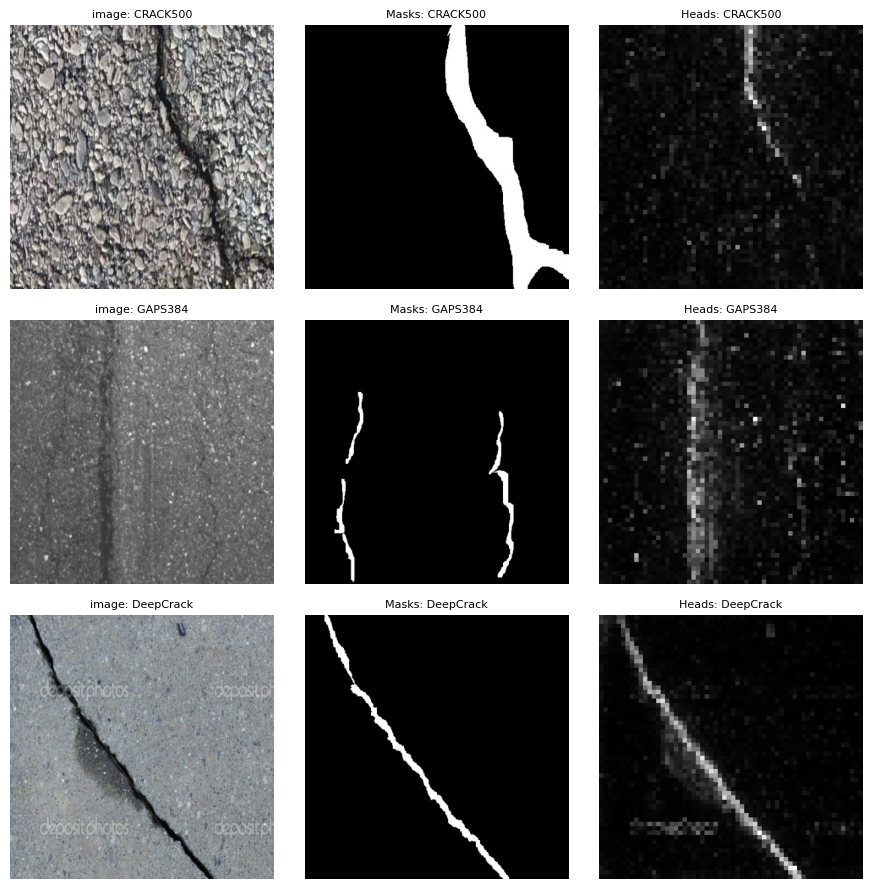

In [10]:
# Cell 9 — What is in the "Heads" folder?
stats = []
for _, row in df.sample(min(200, len(df)), random_state=SEED).iterrows():
    mask = load_mask(row["mask"])
    head_img = Image.open(row["head"]).convert("L")
    head_size = head_img.size                                      # (width, height) as stored
    head = np.array(head_img.resize(mask.shape[::-1], Image.NEAREST))  # resize to the mask's size so pixels line up
    h = head > (127 if head.max() > 1 else 0)
    union = (h | mask).sum()
    stats.append({
        "head_size": f"{head_size[0]}x{head_size[1]}",
        "head_values": len(np.unique(head)),
        "head_pct": 100 * h.mean(),
        "mask_pct": 100 * mask.mean(),
        "iou_with_mask": (h & mask).sum() / union if union else 1.0,
    })
stats = pd.DataFrame(stats)
print(stats["head_size"].value_counts())
print(stats.describe().round(3))

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for r, (_, row) in enumerate(df[df["crack_frac"] > 0.02].sample(3, random_state=SEED).iterrows()):
    for c, (title, path) in enumerate([("image", row["image"]), ("Masks", row["mask"]), ("Heads", row["head"])]):
        axes[r, c].imshow(Image.open(path), cmap="gray")
        axes[r, c].set_title(f"{title}: {row['source']}", fontsize=8)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

In [11]:
# Cell 10 — The dataset's own train/test split: does it leak?
for split, path in sorted(split_files.items()):
    print(f"--- first 3 lines of {split} ---")
    print("\n".join(path.read_text().splitlines()[:3]))

def names_in(path):
    return {Path(m).name for m in re.findall(r"[^\s,]+\.png", path.read_text())}

train_names = names_in(split_files["train.txt"])
test_names = names_in(split_files["test.txt"])
df["official_split"] = np.select(
    [df["name"].isin(train_names), df["name"].isin(test_names)], ["train", "test"], "none")
print(pd.crosstab(df["source"], df["official_split"], margins=True))

parents = df.groupby(["source", "official_split"])["parent"].apply(set).unstack()
leak = pd.DataFrame({
    "test_photos": parents["test"].map(lambda s: len(s) if isinstance(s, set) else 0),
    "also_in_train": [len(t & tr) if isinstance(t, set) and isinstance(tr, set) else 0
                      for t, tr in zip(parents["test"], parents["train"])],
}, index=parents.index)
print("\nTest photos whose other crops are in train:")
print(leak)

--- first 3 lines of test.txt ---
CFD_080.png
CFD_007.png
CFD_111.png
--- first 3 lines of train.txt ---
CFD_103.png
CFD_051.png
CFD_094.png
official_split  test  train   All
source                           
CFD               18    100   118
CRACK500         626   2500  3126
Ceramic           20     80   100
CrackTree200      35    140   175
DeepCrack         89    354   443
GAPS384           77    306   383
Misc              48    192   240
Noncrack         282   1129  1411
Rissbilder       547   2189  2736
Volker            85    342   427
All             1827   7332  9159

Test photos whose other crops are in train:
              test_photos  also_in_train
source                                  
CFD                    18              0
CRACK500              333            333
Ceramic                20              0
CrackTree200           35              0
DeepCrack              57             41
GAPS384                72             40
Misc                   32             28
Non

In [12]:
# Cell 11 — Save the index for the next stages
cols = ["name", "source", "parent", "image", "mask", "width", "height", "crack_frac", "official_split"]
df[cols].to_csv(OUT_DIR / "stage0_index.csv", index=False)
print("Saved", OUT_DIR / "stage0_index.csv", "with", len(df), "rows")

Saved /kaggle/working/stage0_index.csv with 9159 rows
